# Fitting a gamma distribution to a size distribution

A measured size distribution is often summarised by the three parameters of a gamma
distribution, $N_0$, $\mu$ and $\lambda$, because a model or a retrieval needs a closed form. This
notebook writes the gamma form as a probability density scaled by the total concentration, says
what quantity to fit and why, fits it two ways (least squares in log space, and the method of
moments), and sets each fit beside the distribution it came from. It continues the notation of
[01_microphysics_moments](01_microphysics_moments.ipynb), which defines $N_T$, $\Delta N_i$ and
$n(D)$ and computes the bulk quantities; nothing here changes those.

**A note on the references.** The papers cited in this notebook are the ones its author used and learned from, and each contains everything this notebook takes from it. They are not the papers that first derived these definitions.

**What you will learn**

- How the gamma form $n(D) = N_0 D^{\mu} e^{-\lambda D}$ relates to a probability density, what
  $N_0$, $\mu$ and $\lambda$ mean and why $N_0$ is not the total concentration.
- Why the fit is made to $n(D) = \mathrm{d}N/\mathrm{d}D$ at the bin midpoints, not to the per-bin
  concentration.
- A log-space least-squares fit and a method-of-moments fit, and how far each fitted total
  concentration sits from the measured one.
- How a fitted $(\mu, \lambda)$ converts to the effective radius and effective variance of Hansen
  and Travis (1974).

**What data**

> **Every number in this notebook is synthetic.** Section 2's flight is drawn from the same
> fixed-seed random-number generator, with the same seed and the same distribution, as section 1
> of 01_microphysics_moments; section 4's flight is rendered by the package's own synthetic-probe
> generator, so its true distribution is known. No data file is read.

The sections: (1) the gamma form and what to fit; (2) the synthetic flight; (3) a log-space fit
on it; (4) a method-of-moments fit on a flight with a known answer; (5) what to try next.

**Before this:** [01_microphysics_moments](01_microphysics_moments.ipynb) (Comparing microphysics and moments between two products). **Related:** [03_explicit_bin_edges](03_explicit_bin_edges.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The cell below checks that the notebook runs from the repository root, where the later cells find `scripts/`.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/6_science/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## 1. The gamma form and what to fit

**The gamma form.** Written as a probability density, the gamma form puts the
distribution as the total concentration times a normalised shape:

$$n(D) = N_T\, f(D;\mu,\lambda), \qquad f(D;\mu,\lambda) = \frac{\lambda^{\mu+1}}{\Gamma(\mu+1)}\, D^{\mu} e^{-\lambda D}, \quad D > 0,$$

with $\int_0^\infty f\,\mathrm{d}D = 1$. Multiplying out gives the familiar three-parameter form

$$n(D) = N_0\, D^{\mu} e^{-\lambda D}, \qquad N_0 = \frac{N_T\,\lambda^{\mu+1}}{\Gamma(\mu+1)}, \qquad N_T = \int_0^\infty N_0 D^{\mu} e^{-\lambda D}\,\mathrm{d}D = \frac{N_0\,\Gamma(\mu+1)}{\lambda^{\mu+1}} .$$

- The left side, often written $N(D)$, is the number distribution function $n(D) = \mathrm{d}N/\mathrm{d}D$
  (cm$^{-3}\,\mu$m$^{-1}$), *not* a per-bin concentration.
- $N_0$ is the *intercept* parameter, not the total concentration; its units,
  cm$^{-3}\,\mu$m$^{-1-\mu}$, depend on $\mu$. It equals $N_T$ only when $\lambda^{\mu+1} = \Gamma(\mu+1)$.
- $\mu$ is the shape parameter (dimensionless); $\lambda$ is the *rate* (slope) parameter
  ($\mu$m$^{-1}$), the inverse of the scale parameter $1/\lambda$.

**Size distribution versus probability distribution.** $n(D)$ is a concentration density: it
integrates to $N_T$, a number per volume. Dividing by $N_T$ gives $f(D)$, a probability density of
particle size that integrates to 1. A gamma size distribution is a gamma probability density scaled
by $N_T$. By contrast $n(D)/N_0 = D^{\mu} e^{-\lambda D}$ integrates to $\Gamma(\mu+1)/\lambda^{\mu+1}$,
which is generally not 1.

**What to fit.** $x = D_i$ (bin midpoint) and $y = \mathrm{d}N/\mathrm{d}D$ at $D_i$, because the model
$N_0 D^{\mu} e^{-\lambda D}$ *is* a density in $D$. Fitting the per-bin concentration $\Delta N_i$
instead would make wide bins look more populated than narrow ones purely because they are wide, and
the fitted shape would follow the bin layout rather than the cloud. Equivalently, fit $\Delta N_i$
against the model integrated over each bin, $\int_{D_i^-}^{D_i^+} N_0 D^{\mu} e^{-\lambda D}\,\mathrm{d}D$,
the more exact treatment for wide bins.

**Hansen and Travis's gamma form.** Their standard distribution (Eq. 2.56), "a variation of the
gamma distribution", is

$$n(r) = C\, r^{(1-3b)/b}\, e^{-r/(ab)}, \qquad a = r_{\mathrm{eff}}, \quad b = v_{\mathrm{eff}} \quad \text{(Eq. 2.57)},$$

with, per their footnote to Eq. (2.56), $C = N (ab)^{(2b-1)/b} / \Gamma[(1-2b)/b]$ for total
concentration $N$, defined for $0 < b < 0.5$. It is the $(\mu, \lambda)$ form above with
$\mu = (1-3b)/b$ and $\lambda = 1/(ab)$ in radius, so a fitted $(\mu, \lambda)$ converts to an
effective radius and variance: $b = 1/(\mu+3)$, $a = (\mu+3)/\lambda$. The effective radius and variance themselves (Hansen and Travis 1974, Eqs. 2.53-2.54) are
defined in 01_microphysics_moments, section 0.

## 2. The synthetic flight

Two synthetic flights at 1 Hz, built exactly as in 01_microphysics_moments, section 1: 40
log-spaced bins from 55 to 3000 µm, a gamma-shaped true distribution, and two products of one
probe. Only flight W's product A is fitted here; the rest is built so the random sequence, and so
every number, matches 01.

In [2]:
"""1. Two synthetic flights at 1 Hz, each seen by two products of one probe."""
import numpy as np

rng = np.random.default_rng(20261003)

# Bin ladder: 40 log-spaced bins from 55 to 3000 um (edges), midpoints in um.
EDGES = np.geomspace(55.0, 3000.0, 41)
MID = np.sqrt(EDGES[:-1] * EDGES[1:])
N_SEC = 3600

# The two products differ in exactly two ways, both invented and both known here:
#   sample volume per second (litres): B's is 60 % of A's, so B's one-count quantum is larger;
#   detection efficiency: B detects 75 % of the particles below 100 um that A detects.
SV_A, SV_B = 25.0, 15.0
EFF_B = np.where(MID < 100.0, 0.75, 1.0)

def true_psd(n_per_l, dm_um, mu=2.0):
    """Gamma-shaped number per bin (per litre) for a total n_per_l and mean diameter dm_um."""
    shape = MID ** mu * np.exp(-(mu + 1.0) * MID / dm_um) * np.diff(EDGES)
    return n_per_l * shape / shape.sum()

def make_flight(name, temp):
    """A flight: in-cloud mask, the true bin concentration ΔN_i per second, and each product's concentration."""
    cloudy = rng.random(N_SEC) < 0.7
    n_tot = np.where(cloudy, rng.lognormal(np.log(0.8), 0.6, N_SEC), 0.0)       # per litre
    dm = np.where(temp < 0.0, 450.0, 160.0) * rng.lognormal(0.0, 0.2, N_SEC)
    truth = np.array([true_psd(n, d) for n, d in zip(n_tot, dm)])               # (sec, bin)
    counts_a = rng.poisson(truth * SV_A)
    counts_b = rng.poisson(truth * SV_B * EFF_B)
    return {"name": name, "temp": temp, "cloudy": cloudy, "truth": truth,
            "conc_a": counts_a / SV_A, "conc_b": counts_b / SV_B,                # per litre per bin
            "counts_a": counts_a, "counts_b": counts_b}

t = np.arange(N_SEC)
temp_warm = 9.0 + 1.5 * np.sin(2 * np.pi * t / 1800) + rng.normal(0, 0.2, N_SEC)
temp_cold = np.where(t < 1800, 3.0, -9.0) + rng.normal(0, 0.4, N_SEC)          # second half sub-zero
warm = make_flight("flight W (all above 0 C)", temp_warm)
cold = make_flight("flight C (half below 0 C)", temp_cold)
print(f"{len(MID)} bins, {N_SEC} s per flight; in-cloud seconds: "
      f"W {warm['cloudy'].sum()}, C {cold['cloudy'].sum()}")

40 bins, 3600 s per flight; in-cloud seconds: W 2493, C 2505


Product A's in-cloud mean distribution on flight W. The cell takes $\Delta N_i$, divides by
the real bin widths to get $n(D_i)$, and forms $N_T$ as a sum and as a trapezoid integral of $n(D)$;
the fit in section 3 is set against the sum.

In [3]:
"""2. Delta N_i, n(D_i) = Delta N_i / Delta D_i, and N_T two ways, on flight W (product A)."""
dD_um = np.diff(EDGES)                                          # bin widths, um (non-uniform)
dN = warm["conc_a"][warm["cloudy"]].mean(axis=0) / 1e3          # Delta N_i, cm^-3 per bin
n_D = dN / dD_um                                                # n(D_i) = dN/dD, cm^-3 um^-1
trapezoid = getattr(np, "trapezoid", None) or np.trapz          # numpy >= 2 renamed trapz

nt_sum = dN.sum()                                               # sum_i Delta N_i
nt_int = trapezoid(n_D, MID)                                    # integral of n(D) dD, D_1..D_40
print(f"bin widths: {dD_um[0]:.1f} um (first) to {dD_um[-1]:.1f} um (last)")
print(f"N_T = sum of Delta N_i        {nt_sum:.4e} cm^-3")
print(f"N_T = trapezoid of n(D) dD    {nt_int:.4e} cm^-3")
print(f"integral / sum                {nt_int / nt_sum:.3f}   "
      "(the trapezoid spans midpoint to midpoint, so it misses half of each end bin)")

bin widths: 5.8 um (first) to 285.4 um (last)
N_T = sum of Delta N_i        9.6789e-04 cm^-3
N_T = trapezoid of n(D) dD    9.5777e-04 cm^-3
integral / sum                0.990   (the trapezoid spans midpoint to midpoint, so it misses half of each end bin)


## 3. A log-space least-squares fit

The model $\ln n(D) = \ln N_0 + \mu \ln D - \lambda D$ is fitted to $(D_i, \ln n(D_i))$ over the
bins that hold counts, so every decade of $n(D)$ weighs alike. The fitted total is then
integrated twice: from 0 to infinity, $N_0\,\Gamma(\mu+1)/\lambda^{\mu+1}$, and over the probe's
size range only (numerically, on a fine grid), which is the figure comparable with the measured
$N_T$. Because the model is linear in $(\ln N_0, \mu, \lambda)$, the fit is ordinary least squares.

mu = 1.06, lambda = 0.0135 um^-1 (scale 1/lambda = 74 um), N0 = 1.550e-07 cm^-3 um^-(1+mu)
N0 Gamma(mu+1) / lambda^(mu+1)          1.1018e-03 cm^-3  (0 to infinity)
same, integrated over 55-3000 um       9.2635e-04 cm^-3
measured N_T (sum of Delta N_i)         9.6789e-04 cm^-3  ratio fit/measured over the probe's range 0.957


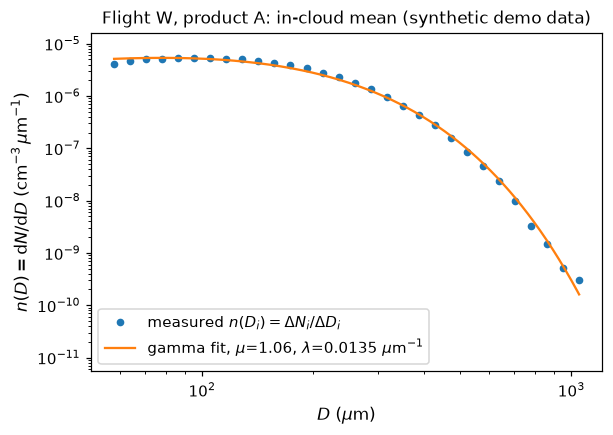

In [4]:
"""3. Gamma fit n(D) = N0 D^mu exp(-lambda D) to (D_i, n(D_i)), residuals in log space."""
from math import gamma as gamma_fn

import matplotlib.pyplot as plt

ok = n_D > 0                                                    # an empty bin has no logarithm

# ln n(D) = ln N0 + mu ln D - lambda D is linear in (ln N0, mu, lambda): ordinary least squares.
design = np.column_stack([np.ones(ok.sum()), np.log(MID[ok]), -MID[ok]])
(log_n0, mu_fit, lam_fit), *_ = np.linalg.lstsq(design, np.log(n_D[ok]), rcond=None)
n0_fit = np.exp(log_n0)
nt_fit_all = n0_fit * gamma_fn(mu_fit + 1) / lam_fit ** (mu_fit + 1)       # integral over 0..inf
d_rng = np.geomspace(EDGES[0], EDGES[-1], 20001)                    # the probe's size range
nt_fit_range = trapezoid(n0_fit * d_rng ** mu_fit * np.exp(-lam_fit * d_rng), d_rng)
print(f"mu = {mu_fit:.2f}, lambda = {lam_fit:.4f} um^-1 (scale 1/lambda = {1 / lam_fit:.0f} um), "
      f"N0 = {n0_fit:.3e} cm^-3 um^-(1+mu)")
print(f"N0 Gamma(mu+1) / lambda^(mu+1)          {nt_fit_all:.4e} cm^-3  (0 to infinity)")
print(f"same, integrated over {EDGES[0]:.0f}-{EDGES[-1]:.0f} um       {nt_fit_range:.4e} cm^-3")
print(f"measured N_T (sum of Delta N_i)         {nt_sum:.4e} cm^-3  "
      f"ratio fit/measured over the probe's range {nt_fit_range / nt_sum:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
d_fine = np.geomspace(MID[ok].min(), MID[ok].max(), 300)     # the fit only where there is data
ax.loglog(MID[ok], n_D[ok], "o", ms=4, label=r"measured $n(D_i)=\Delta N_i/\Delta D_i$")
ax.loglog(d_fine, n0_fit * d_fine ** mu_fit * np.exp(-lam_fit * d_fine),
          label=rf"gamma fit, $\mu$={mu_fit:.2f}, $\lambda$={lam_fit:.4f} $\mu$m$^{{-1}}$")
ax.set_xlabel(r"$D$ ($\mu$m)")
ax.set_ylabel(r"$n(D)=\mathrm{d}N/\mathrm{d}D$ (cm$^{-3}\,\mu$m$^{-1}$)")
# Display only: the y range stops six decades below the peak, where the distribution carries
# information; the bins that hold a single count over the leg sit below it.
ax.set_ylim(n_D.max() * 1e-6, n_D.max() * 3)
ax.set_title("Flight W, product A: in-cloud mean (synthetic demo data)", fontsize=11)
ax.legend(fontsize=10)
plt.show()

*Figure 1. Product A's in-cloud mean number distribution n(D) on flight W (synthetic demo data), in cm⁻³ µm⁻¹ (dots), and the gamma fit to it with log-space residuals (line), drawn over the sizes where the distribution has counts.*

## 4. The method of moments on a flight with a known answer

The imports for the probe renderer and its harness.

In [5]:
"""4. Imports for the known-truth flight (the probe renderer and its harness)."""
import sys
import tempfile

import numpy as np
import xarray as xr   # reads the output files; an example-only dependency, see examples/README.md

from arrayprobe.tools import synthetic_truth as st

sys.path.insert(0, "scripts")
import truth_harness as th  # noqa: E402

### A flight with a known answer

Ten seconds of liquid droplets drawn from a lognormal distribution (median 60 um,
geometric standard deviation 1.8, 15-500 um), spread uniformly through the depth of field
and across the array, at 130 m/s. The generator renders each droplet's diffraction image
as the probe would see it, so out-of-focus droplets image larger or as rings, and droplets
near an array end are clipped. The chain has to cope with all of that.

In [6]:
tmp = tempfile.TemporaryDirectory()
root = Path(tmp.name)
FLIGHT = st.FlightSpec(n_seconds=10, rate_per_s=600.0, seed=3,
                       psd=st.PSD(kind="lognormal", median_um=60.0, gsd=1.8))
raw, manifest = th.build(root / "flight", FLIGHT)
drop = manifest.array("kind") == "droplet"
d_true_um = manifest.array("d0_um")[drop]
volume_cm3 = manifest.sampled_volume_m3() * 1e6
print(f"{d_true_um.size} droplets drawn in {volume_cm3:.1f} cm^3 of sampled air")

5860 droplets drawn in 203112.0 cm^3 of sampled air


### The size distribution

The v3.5 engine decodes, frames and bins the raw file. The project switch `SOCRATES`
selects UIOOPS's 10 um 2D-S bin ladder; the first 128 of its bins span 5 um to 1.285 mm.

In [7]:
paths = th.run_v35(raw, root / "v35", FLIGHT)
# mask_and_scale=False: the raw stored values, as netCDF4's set_auto_mask(False) gives them
with xr.open_dataset(paths["sd"], mask_and_scale=False, decode_times=False) as ds:
    conc = np.nan_to_num(np.asarray(ds["conc_minR"][:], float))[:, : th.NB]   # cm^-4
    count = np.nan_to_num(np.asarray(ds["count"][:], float))[:, : th.NB]
    mid_mm = np.asarray(ds["bin_mid"][:], float)[: th.NB]
    dd_mm = np.asarray(ds["bin_dD"][:], float)[: th.NB]
    t = np.asarray(ds["time"][:], float)
in_flight = np.isin((t // 10000) * 3600 + (t // 100 % 100) * 60 + t % 100,
                    th.flight_seconds(FLIGHT))
conc, count = conc[in_flight], count[in_flight]
edges_um = th.KK_MM * 1000.0
per_bin = conc.mean(axis=0) * dd_mm / 10.0          # cm^-3 per bin, flight mean
print(f"{conc.shape[0]} seconds, {int(count.sum())} particles counted, {th.NB} bins")

10 seconds, 1161 particles counted, 128 bins


The first bins are dropped before fitting: below about 2.5 pixels a 10 µm probe does not
size reliably. The cell below shows the whole size-distribution product the engine wrote.

In [8]:
lower_um = 25.0              # below ~2.5 pixels a 10 um probe does not size reliably
use = edges_um[:-1] >= lower_um
with xr.open_dataset(paths["sd"], decode_times=False) as f:
    ds = f.load()
print(f"conc_minR units: {ds['conc_minR'].attrs.get('units', 'none stated')}; "
      f"{int(use.sum())} of {th.NB} bins used (D >= {lower_um:g} um)")
ds

conc_minR units: cm-4; 126 of 128 bins used (D >= 25 um)


<xarray.Dataset> Size: 848kB
Dimensions:          (Time: 10, CIPcorrlen: 256, CIParealen: 10, Habit: 10)
Dimensions without coordinates: Time, CIPcorrlen, CIParealen, Habit
Data variables: (12/23)
    time             (Time) float64 80B 6.064e+04 6.064e+04 ... 6.065e+04
    bin_min          (CIPcorrlen) float64 2kB 0.005 0.015 0.025 ... 2.545 2.555
    bin_max          (CIPcorrlen) float64 2kB 0.015 0.025 0.035 ... 2.555 2.565
    bin_mid          (CIPcorrlen) float64 2kB 0.01 0.02 0.03 ... 2.54 2.55 2.56
    bin_dD           (CIPcorrlen) float64 2kB 0.01 0.01 0.01 ... 0.01 0.01 0.01
    conc_minR        (Time, CIPcorrlen) float64 20kB 0.0 0.0 1.302 ... 0.0 0.0
    ...               ...
    Prec_rate        (Time, CIPcorrlen) float64 20kB 0.0 0.0 ... 0.0 0.0
    habitmsd         (Time, CIPcorrlen, Habit) float64 205kB 0.0 0.0 ... 0.0 0.0
    Calcd_area       (Time, CIPcorrlen) float64 20kB 0.0 0.0 ... 0.0 0.0
    count            (Time, CIPcorrlen) float64 20kB 0.0 0.0 1.0 ... 0.0 0.0 0.0
    mean_area_ratio  (Time, CIPcorrlen) float64 20kB nan nan 1.0 ... nan nan nan
    mean_perimeter   (Time, CIPcorrlen) float64 20kB nan nan 0.09 ... nan nan
Attributes: (12/14)
    Software:                   UIOOPS_v3.5
    Creation_Time:              synthetic
    Description:                Contains size distributions of particle count...
    Project:                    SOCRATES
    Data_Source:                <tmp>...
    Probe_Type:                 2DS
    ...                         ...
    Dmax Definition:            D of minimum enclosing circle
    Shattering Algorithm:       Applied w/ reacceptance of particles
    Reacceptance Criteria:      D > 50 um; inter-arrival < 1e-06 sec
    Optional Parameters Saved:  None
    arrayprobe_engine:          3.5
    arrayprobe_profile:         unstated

The variable the fit reads, `conc_minR`, is $N(D)$ in cm$^{-4}$ per second and size bin; its
attributes carry the units and the size definition.

In [9]:
ds["conc_minR"]

<xarray.DataArray 'conc_minR' (Time: 10, CIPcorrlen: 256)> Size: 20kB
array([[0.        , 0.        , 1.30162776, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 5.85732494, 1.30162776, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 1.30162776, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 2.60325553, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 5.85732494, 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(10, 256))
Dimensions without coordinates: Time, CIPcorrlen
Attributes:
    units:       cm-4
    long_name:   Size distribution using Dmax
    short_name:  N(Dmax)

### The method-of-moments fit

$N(D) = N_0 D^{\mu} e^{-\lambda D}$ is the usual closed form for a model or a retrieval. The
fit below is the method of moments on $M_1$, $M_2$ and $M_3$. For a gamma distribution
$M_k = N_0\,\Gamma(\mu + k + 1) / \lambda^{\mu + k + 1}$, so $G = M_2^2 / (M_1 M_3) = (\mu + 2) / (\mu + 3)$,
giving $\mu = (3G - 2) / (1 - G)$ and $\lambda = (\mu + 2) M_1 / M_2$. Lower moments are chosen
because the few largest droplets dominate $M_4$ and above. It is notebook code, not a
package function. Nt and the moments here use the same lower size cut,
25 um, as the bulk-quantity section of 01.

mu = 0.51, lambda = 212.7 cm^-1, N0 = 96.3 cm^-(4+mu)


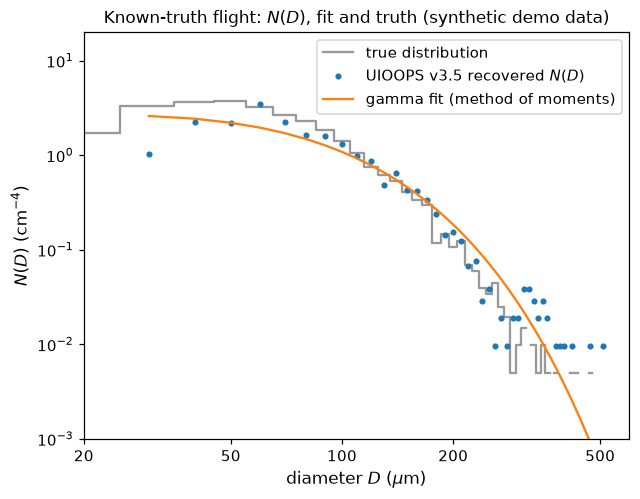

In [10]:
"""4. Method-of-moments gamma fit on the known-truth flight, set beside the truth."""
from math import gamma as gamma_fn


def moment(k):
    return np.sum(np.where(use, per_bin, 0.0) * (mid_mm / 10.0) ** k)    # D in cm


m1, m2, m3 = moment(1), moment(2), moment(3)
g = m2 ** 2 / (m1 * m3)
mu = (3 * g - 2) / (1 - g)
lam = (mu + 2) * m1 / m2                                                  # cm^-1
n0 = m1 * lam ** (mu + 2) / gamma_fn(mu + 2)
print(f"mu = {mu:.2f}, lambda = {lam:.1f} cm^-1, N0 = {n0:.3g} cm^-(4+mu)")

import matplotlib.pyplot as plt  # noqa: E402

d_cm = mid_mm / 10.0
fig, ax = plt.subplots()
true_hist = np.histogram(d_true_um, bins=edges_um)[0] / volume_cm3 / (dd_mm / 10.0)
true_hist[true_hist == 0] = np.nan          # an empty bin has no value on a log axis
ax.step(mid_mm * 1000, true_hist, where="mid", label="true distribution", color="0.6")
ax.plot(mid_mm[use] * 1000, conc.mean(axis=0)[use], "o", ms=3, label="UIOOPS v3.5 recovered $N(D)$")
ax.plot(mid_mm[use] * 1000, n0 * d_cm[use] ** mu * np.exp(-lam * d_cm[use]), label="gamma fit (method of moments)")
ax.set(xscale="log", yscale="log", xlim=(20, 600), ylim=(1e-3, 20), xlabel=r"diameter $D$ ($\mu$m)",
       ylabel=r"$N(D)$ (cm$^{-4}$)")
ax.set_title("Known-truth flight: $N(D)$, fit and truth (synthetic demo data)", fontsize=11)
ax.set_xticks([20, 50, 100, 200, 500], labels=["20", "50", "100", "200", "500"])
ax.minorticks_off()
ax.legend(fontsize=10)
plt.show()

*Figure 2. The known-truth synthetic flight: the true droplet distribution (grey steps), the distribution UIOOPS v3.5 recovers from the rendered probe images (dots), and the method-of-moments gamma fit to it (line), over the bins used for the moments. In the smallest bins the recovered distribution falls below the truth, the optics loss described above.*

## 5. What to try next

- Fit the integrated model instead: minimise the difference between $\Delta N_i$ and
  $\int_{D_i^-}^{D_i^+} N_0 D^{\mu} e^{-\lambda D}\,\mathrm{d}D$, and compare the fitted $\mu$ with
  section 3's on the widest bins.
- Choose the moments M2, M3 and M4, or M0, M1 and M2, in section 4 and see how far $\mu$
  moves; the largest droplets dominate the higher moments.
- Convert section 3's fitted $(\mu, \lambda)$ to an effective radius with $a = (\mu+3)/\lambda$ and
  compare it with the effective diameter that
  [01_microphysics_moments](01_microphysics_moments.ipynb) computes from the bins.
- Re-bin onto a coarser grid with [03_explicit_bin_edges](03_explicit_bin_edges.ipynb) and
  refit, to see how much the bin layout moves the fit.

## References

- Hansen, J. E. and Travis, L. D. (1974). Light scattering in planetary atmospheres. *Space Sci.
  Rev.*, 16, 527-610. Eqs. (2.56)-(2.57): the standard
  gamma-type size distribution and its parameters.